In [363]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
from scipy.signal import hilbert
from daspy.basic_tools.filter import bandpass
from daspy.basic_tools.preprocessing import normalization, downsampling
from daspy.advanced_tools.denoising import common_mode_noise_removal
from daspy.advanced_tools.decomposition import fk_filter as daspy_fk_filter
from daspy.basic_tools.visualization import plot

In [364]:
def read_bin(path, start_seconds=0.0, duration=60.0, padding_seconds=100.0):
    """读取目标时间窗及前后可用上下文，只返回数据数组（通道 × 时间）。"""
    source = Path(path).expanduser().resolve()  # 参考文件或目录的绝对路径
    if source.is_dir():
        files = sorted(source.glob('*.bin'))  # 目录内按文件名排列的文件
        if not files:
            raise FileNotFoundError(f'目录中没有 BIN：{source}')
        source = files[0]
    files = sorted(source.parent.glob('*.bin'))
    headers = []  # 所有文件的 20 个 float32 文件头
    for file in files:
        header = np.fromfile(file, dtype='<f4', count=20)
        headers.append(header)
    anchor = files.index(source)  # 参考文件在列表中的位置
    rate = float(headers[anchor][9])  # 采样率，Hz
    channels = int(headers[anchor][8])  # 总通道数
    frames = []  # 每个文件每通道的采样点数
    for file, header in zip(files, headers):
        count = int(header[7])  # 当前文件每通道的采样点数
        if count <= 0 or header[7] != count or header[8] != channels or header[9] != rate:
            raise ValueError(f'文件长度、通道数或采样率不一致：{file.name}')
        if file.stat().st_size != 80 + channels * count * 4:
            raise ValueError(f'文件头与数据体长度不一致：{file.name}')
        frames.append(count)
    boundaries = np.r_[0, np.cumsum(frames)]  # 全目录各文件的采样边界
    anchor_sample = int(boundaries[anchor])  # 参考文件的全局起点
    target_first = anchor_sample + round(start_seconds * rate)  # 目标区间起点，一般都是开头呗，0开始
    target_last = target_first + round(duration * rate)  # 目标区间终点，不包含
    if target_first < 0 or target_last > boundaries[-1] or target_first >= target_last:
        raise ValueError('请求的时间区间超出实际数据范围')
    first = max(0, target_first - round(padding_seconds * rate))  # 含前置上下文的起点
    last = min(int(boundaries[-1]), target_last + round(padding_seconds * rate))  # 含后置上下文的终点
    blocks = []  # 各文件中需要读取的真实数据片段
    for index, file in enumerate(files):
        left = max(first, int(boundaries[index]))
        right = min(last, int(boundaries[index + 1]))
        if left < right:
            mapped = np.memmap(file, dtype='<f4', mode='r', offset=80,
                               shape=(channels, frames[index]))  # 跳过文件头，只读映射
            blocks.append(mapped[:, left - boundaries[index]:right - boundaries[index]])
    return np.concatenate(blocks, axis=1)

In [365]:
def filter_data(data, sampling_rate, frequency_low=0.01, frequency_high=1.0,
                remove_common=True, normalize=True, detrend=True, 
                use_envelope=True, envelope_smoothing=0.25):
    from daspy.basic_tools.preprocessing import detrending
    
    # 1. 去趋势 去除长时间漂移和直流偏移
    working_data = data
    if detrend:
        detrended = np.empty_like(data, dtype=np.float32)
        for row in range(len(data)):
            detrended[row] = detrending(data[row])
        working_data = detrended
    
    # 2. 带通滤波
    filtered = np.empty_like(working_data, dtype=np.float32)
    for row in range(0, len(working_data), 8):  # 分批处理，减少临时内存占用
        filtered[row:row + 8] = bandpass(
            working_data[row:row + 8], fs=sampling_rate, freqmin=frequency_low,
            freqmax=frequency_high, corners=4, zerophase=True)
    
    # 3. 共模噪声去除
    if remove_common:
        # DASPy 内部会除以共模能量；全零共模时跳过，避免产生 NaN。
        common = np.median(filtered, axis=0)
        if np.sum(common.astype(float) ** 2) > np.finfo(float).eps:
            filtered = common_mode_noise_removal(filtered, method='median')
    
    # 4. Hilbert包络提取（可选，TTMuTian方法）
    if use_envelope:
        envelope = np.empty_like(filtered, dtype=np.float32)
        for row in range(len(filtered)):
            # Hilbert变换获取解析信号
            analytic_signal = hilbert(filtered[row])
            # 提取瞬时幅度（包络）
            amplitude = np.abs(analytic_signal)
            # 高斯平滑去除快速振荡
            if envelope_smoothing > 0:
                sigma = envelope_smoothing * sampling_rate  # 秒 → 采样点
                amplitude = gaussian_filter1d(amplitude, sigma=sigma, mode='nearest')
            envelope[row] = amplitude
        filtered = envelope
    
    # 5. MAD归一化
    if normalize:
        filtered = normalization(filtered, method='MAD')
    
    return filtered


def filter_fk(data, sampling_rate, channel_spacing=4.0,
              direction='decreasing', minimum_speed_kmh=0.0, maximum_speed_kmh=120.0):
    """调用 DASPy 的 f-k 滤波，保留指定方向及速度范围。
    
    参数说明：
    - direction: 'increasing'=通道递增(左下→右上), 'decreasing'=通道递减(左上→右下), 'both'=双向
    - minimum_speed_kmh: 最小速度(km/h)，默认0即可
    - maximum_speed_kmh: 最大速度(km/h)，应该大于实际车速
    
    注意：vmin和vmax定义的是**速度绝对值范围**，不是视速度的正负范围
    """
    if direction not in ['decreasing', 'increasing', 'both']:
        raise ValueError('direction 必须为 decreasing、increasing 或 both')
    
    # 修正映射：increasing对应正视速度(flag=1)，decreasing对应负视速度(flag=-1)
    flag = {'increasing': 1, 'decreasing': -1, 'both': 0}[direction]
    
    # 速度转换 km/h -> m/s
    vmin = minimum_speed_kmh / 3.6
    vmax = maximum_speed_kmh / 3.6
    
    return daspy_fk_filter(
        data, dx=channel_spacing, fs=sampling_rate, mode='retain', flag=flag,
        vmin=vmin, vmax=vmax,  # 改为直接使用min/max，不用95%的窄带
        taper=(0.02, 0.05), pad='default').astype(np.float32)

In [366]:
def process(source_path, start_seconds=0.0, duration=60.0,
            channel_from=291, channel_to=520, downsample_factor=50,
            frequency_low=0.01, frequency_high=1.0,
            remove_common=True, normalize=True, detrend=True, 
            use_envelope=True, envelope_smoothing=0.25,  # 新增Hilbert包络参数
            use_fk=True, direction='decreasing', channel_spacing=4.0,
            minimum_speed_kmh=0.0, maximum_speed_kmh=120.0, padding_seconds=100.0):
    """完整的DAS数据处理流程
    
    新增参数：
        use_envelope: 是否使用Hilbert包络（TTMuTian方法）
        envelope_smoothing: 包络平滑窗口（秒）
    """

    # 1. 直接从给定 BIN 文件的文件头读取采样率。
    sampling_rate = float(np.fromfile(source_path, dtype='<f4', count=20)[9])

    # 计算跨文件读取时实际可用的前置上下文。
    source = Path(source_path).expanduser().resolve()
    files = sorted(source.parent.glob('*.bin'))
    samples_before = sum(int(np.fromfile(file, dtype='<f4', count=20)[7])
                         for file in files[:files.index(source)])
    # 前置上下文以原始采样点计数；数据开头不足时，按实际可用长度计算。
    padding_before = min(round(padding_seconds * sampling_rate),
                         samples_before + round(start_seconds * sampling_rate))
    data = read_bin(source, start_seconds, duration, padding_seconds)

    # 2. DASPy 时间降采样，先做抗混叠低通，再抽取。
    if downsample_factor > 1:
        data = downsampling(data, tint=downsample_factor)
        sampling_rate /= downsample_factor

    # 3. 全通道预处理（去趋势、带通、去共模、可选包络、归一化）
    data = filter_data(data, sampling_rate, frequency_low, frequency_high,
                       remove_common=remove_common, normalize=normalize, detrend=detrend,
                       use_envelope=use_envelope, envelope_smoothing=envelope_smoothing)
    
    # 4. 通道选择
    data = data[channel_from - 1:channel_to]
    
    # 5. 可选的F-K滤波
    if use_fk:
        data = filter_fk(data, sampling_rate, channel_spacing,
                         direction, minimum_speed_kmh, maximum_speed_kmh)

    # 6. 按当前采样率定位目标窗口，去掉滤波上下文。
    first = round(padding_before / downsample_factor)
    last = first + round(duration * sampling_rate)
    return data[:, first:last].copy(), sampling_rate

In [367]:
def plot_data(data, sampling_rate, start_seconds=0.0, channel_from=1,
              figsize=(12, 5), cmap='RdBu_r', vmax_per=99):
    """绘制处理好的数据（通道 × 时间）；sampling_rate 为处理后的采样率。"""
    fig, ax = plt.subplots(figsize=figsize)
    plot(data, fs=sampling_rate, ax=ax, xmode='channel', transpose=True,
         t0=start_seconds, x0=channel_from, cmap=cmap, vmax_per=vmax_per)
    fig.tight_layout()
    plt.show()
    return fig, ax

数据形状：(520, 4800)，采样率：20 Hz


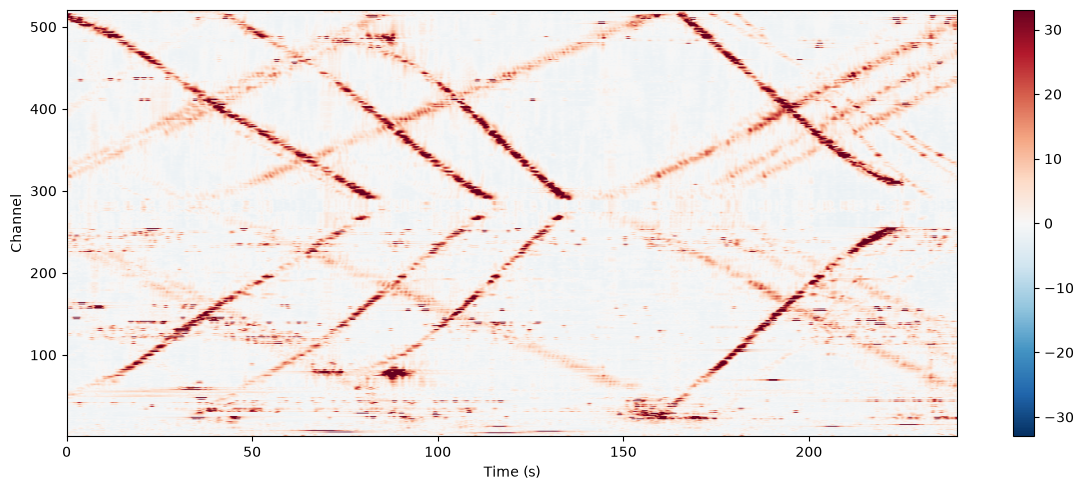

In [368]:
source_path = Path(r'D:\projects\das\下午\ch1_2026-09-05-13-51-27_2_30720_520_1000.bin')
start_seconds = 0.0
duration = 240.0
channel_from, channel_to = 1, 520

data, sampling_rate = process(
    source_path, start_seconds=start_seconds, duration=duration,
    channel_from=channel_from, channel_to=channel_to,
    downsample_factor=50,
    frequency_low=0.01, frequency_high=1.0,
    use_fk=False, direction='both',
    use_envelope=True, envelope_smoothing=0.25,
    channel_spacing=4.0, maximum_speed_kmh=120.0,
    padding_seconds=100.0,
)
print(f'数据形状：{data.shape}，采样率：{sampling_rate:g} Hz')
plt.style.use('default')
fig, ax = plot_data(data, sampling_rate,
                    start_seconds=start_seconds, channel_from=channel_from)


In [369]:
# source_path = Path(r'D:\projects\das\下午\ch1_2026-09-05-13-51-27_2_30720_520_1000.bin')
# start_seconds = 50.0
# duration = 240.0
# channel_from, channel_to = 50, 520
#
# data, sampling_rate = process(
#     source_path, start_seconds=start_seconds, duration=duration,
#     channel_from=channel_from, channel_to=channel_to,
#     downsample_factor=50,
#     frequency_low=0.01, frequency_high=1.0,
#     use_fk=False, direction='both',
#     use_envelope=False, envelope_smoothing=0.25,
#     channel_spacing=4.0, maximum_speed_kmh=120.0,
#     padding_seconds=100.0,
# )
# print(f'数据形状：{data.shape}，采样率：{sampling_rate:g} Hz')
# plt.style.use('default')
# fig, ax = plot_data(data, sampling_rate,
#                     start_seconds=start_seconds, channel_from=channel_from)


In [370]:
# source_path = Path(r'D:\projects\das\下午\ch1_2026-09-05-13-51-27_2_30720_520_1000.bin')
# start_seconds = 0.0
# duration = 240.0
# channel_from, channel_to = 280, 520
#
# data, sampling_rate = process(
#     source_path, start_seconds=start_seconds, duration=duration,
#     channel_from=channel_from, channel_to=channel_to,
#     downsample_factor=50,
#     frequency_low=0.01, frequency_high=1.0,
#     use_fk=True, direction='both',
#     use_envelope=True, envelope_smoothing=0.25,
#     channel_spacing=4.0, maximum_speed_kmh=200.0,
#     padding_seconds=100.0,
# )
# print(f'数据形状：{data.shape}，采样率：{sampling_rate:g} Hz')
# plt.style.use('default')
# fig, ax = plot_data(data, sampling_rate,
#                     start_seconds=start_seconds, channel_from=channel_from)


In [371]:
# source_path = Path(r'D:\projects\das\下午\ch1_2026-09-05-13-51-27_2_30720_520_1000.bin')
# start_seconds = 0.0
# duration = 240.0
# channel_from, channel_to = 50, 280
#
# data, sampling_rate = process(
#     source_path, start_seconds=start_seconds, duration=duration,
#     channel_from=channel_from, channel_to=channel_to,
#     downsample_factor=50,
#     frequency_low=0.01, frequency_high=1.0,
#     use_fk=True, direction='both',
#     use_envelope=True, envelope_smoothing=0.25,
#     channel_spacing=4.0, maximum_speed_kmh=200.0,
#     padding_seconds=100.0,
# )
# print(f'数据形状：{data.shape}，采样率：{sampling_rate:g} Hz')
# plt.style.use('default')
# fig, ax = plot_data(data, sampling_rate,
#                     start_seconds=start_seconds, channel_from=channel_from)

In [372]:
# from skimage.filters import frangi
# from skimage.morphology import skeletonize, remove_small_objects
# from skimage.measure import label, regionprops
#
# def ridge_detection_frangi(data, sigmas=range(1, 5), threshold_percentile=95):
#     """使用Frangi滤波器检测脊线（血管检测算法）"""
#     ridge_response = frangi(
#         data,
#         sigmas=sigmas,        # 多尺度检测
#         alpha=0.9,            # 板状vs管状权重
#         beta=0.5,             # 二阶导数权重
#         gamma=15,             # Hessian归一化
#         black_ridges=False    # 检测亮脊线
#     )
#     threshold = np.percentile(ridge_response, threshold_percentile)
#     ridge_mask = ridge_response > threshold
#     return ridge_response, ridge_mask
#
#
# def extract_skeleton(ridge_mask, min_size=50):
#     # 去除小噪声块
#     cleaned = remove_small_objects(ridge_mask, min_size=min_size)
#     # 骨架化（Zhang-Suen算法）
#     skeleton = skeletonize(cleaned)
#     return skeleton
#
#
# def skeleton_to_tracks(skeleton, min_length=50):
#     # 连通域标记（8连通）
#     labeled = label(skeleton, connectivity=2)
#     regions = regionprops(labeled)
#     print(f"  找到 {len(regions)} 个连通域")
#     tracks = []
#     for region in regions:
#         coords = region.coords  # (N, 2) - [channel, time]
#         if len(coords) < min_length:
#             continue
#         # 按时间排序
#         sorted_idx = np.argsort(coords[:, 1])
#         coords_sorted = coords[sorted_idx]
#         track = {
#             "channels": coords_sorted[:, 0],
#             "times": coords_sorted[:, 1],
#             "length": len(coords_sorted)
#         }
#         tracks.append(track)
#     print(f"  提取 {len(tracks)} 条轨迹（长度 >= {min_length}）")
#     return tracks
#
#
# def ridge_based_tracking(data, sigmas=range(1, 5), min_size=50, min_length=50):
#     """完整的脊线检测轨迹提取"""
#     # 1. 脊线检测
#     ridge_response, ridge_mask = ridge_detection_frangi(data, sigmas=sigmas)
#     # 2. 骨架提取
#     skeleton = extract_skeleton(ridge_mask, min_size=min_size)
#     # 3. 轨迹提取
#     tracks = skeleton_to_tracks(skeleton, min_length=min_length)
#     return tracks, ridge_response, skeleton

In [373]:
# source_path = Path(r"D:\projects\das\下午\ch1_2026-09-05-13-51-27_2_30720_520_1000.bin")
# start_seconds = 0.0
# duration = 240.0
# channel_from, channel_to = 51, 520
# # 预处理：包络 + F-K滤波
# data, sampling_rate = process(
#     source_path,
#     start_seconds=start_seconds,
#     duration=duration,
#     channel_from=channel_from,
#     channel_to=channel_to,
#     downsample_factor=50,
#     frequency_low=0.01,
#     frequency_high=1.0,
#     use_envelope=True,
#     envelope_smoothing=0.25,
#     use_fk=True,
#     direction="decreasing",
#     channel_spacing=4.0,
#     maximum_speed_kmh=120.0,
#     padding_seconds=100.0,
# )
# print(f"数据形状: {data.shape}, 采样率: {sampling_rate} Hz\n")
# # 脊线检测参数
# ridge_params = {
#     "sigmas": range(1, 6),  # 检测尺度1-5
#     "min_size": 30,         # 最小连通域30像素
#     "min_length": 40,       # 最小轨迹长度40通道
# }
# # 执行脊线检测
# tracks_ridge, ridge_response, skeleton = ridge_based_tracking(
#     data,
#     sigmas=ridge_params["sigmas"],
#     min_size=ridge_params["min_size"],
#     min_length=ridge_params["min_length"]
# )
# if len(tracks_ridge) > 0:
#     for i, track in enumerate(tracks_ridge):
#         # 计算速度
#         distance = (
#             track["channels"][-1] - track["channels"][0]
#         ) * 4.0
#         time = (
#             track["times"][-1] - track["times"][0]
#         ) / sampling_rate
#         speed_kmh = (distance / time) * 3.6 if time > 0 else 0
#         print(
#             f'  轨迹 {i+1}: {track["length"]} 通道, '
#             f"速度 {speed_kmh:.1f} km/h"
#         )
# # 创建4子图可视化
# fig, axes = plt.subplots(
#     2, 2,
#     figsize=(16, 10),
#     sharex=True,
#     sharey=True
# )
# axes = axes.ravel()
# extent = [
#     0,
#     data.shape[1] / sampling_rate,
#     channel_from,
#     channel_from + data.shape[0]
# ]
# # 1. 原始数据
# vmax = np.percentile(np.abs(data), 99)
# axes[0].imshow(
#     data,
#     aspect="auto",
#     cmap="RdBu_r",
#     extent=extent,
#     vmin=-vmax,
#     vmax=vmax,
#     origin="lower",
#     interpolation="none"
# )
# axes[0].set_title(
#     "1. Original Data (Envelope + FK)",
#     fontweight="bold"
# )
# axes[0].set_ylabel("Channel")
# # 2. 脊线响应
# axes[1].imshow(
#     ridge_response,
#     aspect="auto",
#     cmap="hot",
#     extent=extent,
#     origin="lower",
#     interpolation="none"
# )
# axes[1].set_title(
#     "2. Ridge Response (Frangi Filter)",
#     fontweight="bold"
# )
# # 3. 骨架
# axes[2].imshow(
#     skeleton,
#     aspect="auto",
#     cmap="gray",
#     extent=extent,
#     origin="lower",
#     interpolation="none"
# )
# axes[2].set_title(
#     "3. Skeleton (Skeletonize)",
#     fontweight="bold"
# )
# axes[2].set_ylabel("Channel")
# axes[2].set_xlabel("Time (s)")
# # 4. 提取的轨迹
# axes[3].imshow(
#     data,
#     aspect="auto",
#     cmap="RdBu_r",
#     extent=extent,
#     vmin=-vmax,
#     vmax=vmax,
#     origin="lower",
#     interpolation="none",
#     alpha=0.5
# )
# colors = plt.cm.tab10(
#     np.linspace(0, 1, len(tracks_ridge))
# )
# for i, (track, color) in enumerate(zip(tracks_ridge, colors)):
#     channels = track["channels"] + channel_from
#     times = track["times"] / sampling_rate
#     axes[3].plot(
#         times,
#         channels,
#         "o-",
#         color=color,
#         linewidth=2.5,
#         markersize=4,
#         label=f'Track {i+1} ({track["length"]}ch)',
#         alpha=0.9,
#         markeredgecolor="white",
#         markeredgewidth=0.5
#     )
# axes[3].set_title(
#     f"4. Extracted Tracks ({len(tracks_ridge)} tracks)",
#     fontweight="bold"
# )
# axes[3].set_xlabel("Time (s)")
#
# # if len(tracks_ridge) > 0:
# #     axes[3].legend(
# #         loc="upper right",
# #         fontsize=9
# #     )
# plt.tight_layout()
# plt.show()

In [ ]:
from scipy import signal as sp_signal
from scipy.ndimage import maximum_filter

def find_peaks_simple(data, sampling_rate, prominence=2.5, min_separation_seconds=1.0):
    """在每个通道上找峰值"""
    min_distance = int(min_separation_seconds * sampling_rate)
    peaks_list = []

    for channel_data in data:
        peaks, _ = sp_signal.find_peaks(
            channel_data,
            prominence=prominence,
            distance=min_distance
        )
        peaks_list.append(peaks)

    return peaks_list


def peaks_to_binary(peaks_list, shape):
    """峰值列表转二值图"""
    binary = np.zeros(shape, dtype=bool)
    for i, peaks in enumerate(peaks_list):
        if len(peaks) > 0:
            binary[i, peaks] = True
    return binary

def filter_isolated_peaks(peaks_list, shape, sampling_rate,
                          channel_radius=5, time_radius_seconds=3.0,
                          min_other_channels=3):
    """保留在时空邻域内得到至少 min_other_channels 个其他通道支持的峰。

    每个通道最多贡献一次支持；只根据原始峰筛一轮，不递归删除。
    返回值仍为每通道的采样点索引列表，可直接传给 peaks_to_binary。
    """
    from scipy.ndimage import maximum_filter1d, convolve1d

    if len(shape) != 2 or len(peaks_list) != shape[0]:
        raise ValueError('shape 必须为 (通道数, 采样点数)，并与 peaks_list 一致')
    if not np.isfinite(sampling_rate) or sampling_rate <= 0:
        raise ValueError('sampling_rate 必须为有限正数')
    if (not np.isfinite(time_radius_seconds) or time_radius_seconds < 0
            or not isinstance(channel_radius, (int, np.integer)) or channel_radius < 0
            or not isinstance(min_other_channels, (int, np.integer)) or min_other_channels < 0):
        raise ValueError('邻域半径和最少支持通道数必须为非负数，通道参数必须为整数')
    if 0 in shape:
        return [np.array([], dtype=int) for _ in peaks_list]

    binary = peaks_to_binary(peaks_list, shape)
    time_radius = int(np.floor(time_radius_seconds * sampling_rate + 1e-9))
    # 对每个时间位置，标记每个通道在前后时间范围内是否出现过峰。
    nearby = maximum_filter1d(binary.astype(np.int32),
                              size=2 * time_radius + 1, axis=1,
                              mode='constant', cval=0)
    # 沿通道方向累计支持数，减去本通道，避免自身或本通道多个峰凑数。
    support = convolve1d(nearby, np.ones(2 * channel_radius + 1, dtype=np.int32),
                         axis=0, mode='constant', cval=0) - nearby
    keep = binary & (support >= min_other_channels)
    return [np.flatnonzero(row) for row in keep]


In [ ]:
# 峰值检测 → 邻近通道支持筛选 → 可视化（横轴时间、纵轴通道）。
raw_peaks_list = find_peaks_simple(data, sampling_rate, prominence=2.5, min_separation_seconds=3.0)

# 初筛参数：前后各 5 个通道、前后各 3 秒，至少 3 个其他通道支持。
# 这些是调参起点；慢速轨迹可适当增大时间半径。
peaks_list = filter_isolated_peaks(
    raw_peaks_list, data.shape, sampling_rate,
    channel_radius=5, time_radius_seconds=3.0, min_other_channels=3,
)
raw_total_peaks = sum(len(p) for p in raw_peaks_list)
total_peaks = sum(len(p) for p in peaks_list)
print(f'原始 {raw_total_peaks} 个峰，保留 {total_peaks} 个，删除 {raw_total_peaks - total_peaks} 个')

fig, ax = plt.subplots(figsize=(12, 5))
plot(data, fs=sampling_rate, ax=ax, xmode='channel', transpose=True,
     t0=start_seconds, x0=channel_from, cmap='RdBu_r', vmax_per=99)

for row, (raw_peaks, peaks) in enumerate(zip(raw_peaks_list, peaks_list)):
    removed = np.setdiff1d(raw_peaks, peaks)
    ax.scatter(removed / sampling_rate + start_seconds,
               np.full(len(removed), channel_from + row),
               s=6, c='gray', alpha=0.4, zorder=4,
               label='Removed' if row == 0 else None)
    peak_times = peaks / sampling_rate + start_seconds
    peak_channels = np.full(len(peaks), channel_from + row)
    ax.scatter(peak_times, peak_channels, s=8, c='yellow',
               edgecolors='black', linewidths=0.3, zorder=5, alpha=0.7,
               label='Kept' if row == 0 else None)

ax.set_title(f'Peaks: {total_peaks} kept / {raw_total_peaks} raw', fontweight='bold')
ax.legend(loc='upper right')
fig.tight_layout()
plt.show()


In [376]:
def hough_transform_simple(binary_image, channel_window=80, theta_bins=180):
    """局部霍夫变换找轨迹种子"""
    channels, samples = binary_image.shape
    seeds = []
    
    # 角度范围：主要关注斜线（±30°到±60°）
    theta_range = np.linspace(-np.pi/3, np.pi/3, theta_bins)
    
    # 滑动窗口
    overlap = channel_window // 2
    for ch_start in range(0, channels - channel_window + 1, overlap):
        ch_end = min(ch_start + channel_window, channels)
        window = binary_image[ch_start:ch_end, :]
        
        if window.sum() < 3:  # 至少3个峰值
            continue
        
        # 获取峰值坐标
        coords = np.argwhere(window)  # (N, 2) - [channel, time]
        if len(coords) < 3:
            continue
        
        # 霍夫变换累加器
        max_rho = int(np.sqrt(channel_window**2 + samples**2))
        accumulator = np.zeros((2 * max_rho, theta_bins), dtype=int)
        
        for ch, t in coords:
            for theta_idx, theta in enumerate(theta_range):
                rho = int(ch * np.cos(theta) + t * np.sin(theta))
                rho_idx = rho + max_rho
                if 0 <= rho_idx < accumulator.shape[0]:
                    accumulator[rho_idx, theta_idx] += 1
        
        # 找局部最大值
        threshold = max(3, int(0.3 * len(coords)))  # 至少30%的点支持
        local_max = maximum_filter(accumulator, size=5)
        peaks_mask = (accumulator >= threshold) & (accumulator == local_max)
        
        peak_coords = np.argwhere(peaks_mask)
        
        for rho_idx, theta_idx in peak_coords:
            rho = rho_idx - max_rho
            theta = theta_range[theta_idx]
            votes = accumulator[rho_idx, theta_idx]
            
            # 转换为起止点
            if abs(np.sin(theta)) > 0.01:
                t_start = (rho - 0 * np.cos(theta)) / np.sin(theta)
                t_end = (rho - (ch_end - ch_start) * np.cos(theta)) / np.sin(theta)
                
                if 0 <= t_start < samples and 0 <= t_end < samples:
                    seeds.append({
                        "ch_start": ch_start,
                        "t_start": int(t_start),
                        "ch_end": ch_end - 1,
                        "t_end": int(t_end),
                        "votes": votes
                    })
    
    return seeds


In [377]:
# ========== 轨迹延伸 ==========

def extend_track(seed, binary_image, max_gap=20):
    """从霍夫种子延伸完整轨迹"""
    channels, samples = binary_image.shape
    
    ch_start, ch_end = seed["ch_start"], seed["ch_end"]
    t_start, t_end = seed["t_start"], seed["t_end"]
    
    # 计算斜率
    if ch_end != ch_start:
        slope = (t_end - t_start) / (ch_end - ch_start)
    else:
        slope = 0
    
    track_channels = []
    track_times = []
    
    # 从起始通道向两边延伸
    direction = 1 if ch_end > ch_start else -1
    current_ch = ch_start
    consecutive_misses = 0
    
    while 0 <= current_ch < channels and consecutive_misses < max_gap:
        # 预测时间位置
        if len(track_channels) > 0:
            # 用线性外推
            predicted_t = track_times[-1] + direction * int(slope)
        else:
            predicted_t = t_start
        
        # 在预测位置附近搜索峰值
        search_window = 20
        t_min = max(0, predicted_t - search_window)
        t_max = min(samples, predicted_t + search_window)
        
        if binary_image[current_ch, t_min:t_max].any():
            # 找到峰值
            local_peaks = np.where(binary_image[current_ch, t_min:t_max])[0]
            best_peak_t = t_min + local_peaks[np.argmin(np.abs(local_peaks + t_min - predicted_t))]
            
            track_channels.append(current_ch)
            track_times.append(best_peak_t)
            consecutive_misses = 0
        else:
            consecutive_misses += 1
        
        current_ch += direction
    
    if len(track_channels) < 10:
        return None
    
    return {
        "channels": np.array(track_channels),
        "times": np.array(track_times),
        "length": len(track_channels)
    }


In [378]:
# ========== 完整轨迹提取流程 ==========

def extract_tracks(data, sampling_rate, params):
    """峰值检测 + 霍夫变换 + 轨迹延伸"""
    print("1. 峰值检测...")
    peaks_list = find_peaks_simple(
        data, sampling_rate,
        prominence=params.get("prominence", 2.5),
        min_separation_seconds=params.get("min_separation", 2.0)
    )
    
    total_peaks = sum(len(p) for p in peaks_list)
    print(f"   找到 {total_peaks} 个峰值")
    
    # 转换为二值图
    binary = peaks_to_binary(peaks_list, data.shape)
    
    # 霍夫变换
    print("2. 霍夫变换...")
    seeds = hough_transform_simple(
        binary,
        channel_window=params.get("channel_window", 80)
    )
    print(f"   找到 {len(seeds)} 个种子")
    
    # 延伸轨迹
    print("3. 轨迹延伸...")
    tracks = []
    for seed in seeds:
        track = extend_track(
            seed, binary,
            max_gap=params.get("max_gap", 20)
        )
        if track is not None:
            min_length = params.get("min_track_length", 50)
            if track["length"] >= min_length:
                tracks.append(track)
    
    print(f"   提取 {len(tracks)} 条轨迹")
    
    # 简单去重：按起始通道去重
    if len(tracks) > 1:
        tracks = sorted(tracks, key=lambda t: (t["channels"][0], -t["length"]))
        unique_tracks = [tracks[0]]
        for track in tracks[1:]:
            # 如果起始通道相差>10，认为是不同轨迹
            if abs(track["channels"][0] - unique_tracks[-1]["channels"][0]) > 10:
                unique_tracks.append(track)
        tracks = unique_tracks
        print(f"   去重后 {len(tracks)} 条轨迹")
    
    return tracks, binary


def plot_tracks(data, tracks, sampling_rate, channel_from=1, title="Vehicle Tracks"):
    """绘制轨迹叠加在数据上"""
    fig, ax = plt.subplots(figsize=(14, 8))
    
    # 绘制数据
    extent = [0, data.shape[1] / sampling_rate,
              channel_from, channel_from + data.shape[0]]
    vmax = np.percentile(np.abs(data), 99)
    
    ax.imshow(data, aspect="auto", cmap="RdBu_r",
             extent=extent, vmin=-vmax, vmax=vmax,
             origin="lower", interpolation="none")
    
    # 绘制轨迹
    colors = plt.cm.tab10(np.linspace(0, 1, len(tracks)))
    
    for i, (track, color) in enumerate(zip(tracks, colors)):
        channels = track["channels"] + channel_from
        times = track["times"] / sampling_rate
        
        ax.plot(times, channels, "o-", color=color, linewidth=2.5,
               markersize=5, label=f"Track {i+1} ({track["length"]}ch)",
               alpha=0.9, markeredgecolor="white", markeredgewidth=0.5)
    
    ax.set_xlabel("Time (s)", fontsize=11)
    ax.set_ylabel("Channel", fontsize=11)
    ax.set_title(title, fontweight="bold", fontsize=12)
    if len(tracks) > 0:
        ax.legend(loc="upper right", fontsize=9)
    ax.grid(alpha=0.3, linestyle="--")
    
    plt.tight_layout()
    return fig


In [379]:
source_path = Path(r"D:\projects\das\下午\ch1_2026-09-05-13-51-27_2_30720_520_1000.bin")
start_seconds = 0.0
duration = 240.0
channel_from, channel_to = 281, 520

# 1. 数据预处理
data, sampling_rate = process(
    source_path, start_seconds=start_seconds, duration=duration,
    channel_from=channel_from, channel_to=channel_to,
    downsample_factor=50,
    frequency_low=0.01, frequency_high=1.0,
    use_envelope=True,         # 使用Hilbert包络
    envelope_smoothing=0.25,
    use_fk=True,               # 使用F-K滤波
    direction="both",    # 只保留decreasing方向
    channel_spacing=4.0,
    maximum_speed_kmh=120.0,
    padding_seconds=100.0,
)

# 2. 轨迹提取参数
track_params = {
    "peak_method": "simple",           # 峰值检测方法: simple 或 ridge
    "prominence": 2.5,                 # 峰值突出度
    "min_separation": 1.0,             # 峰值最小间隔（秒）
    "hough_channel_window": 60,       # 霍夫变换通道窗口
    "hough_overlap": 30,              # 窗口重叠
    "max_gap": 20,                    # 最大连续缺失通道数
    "poly_degree": 1,                 # 多项式拟合次数（1=直线，2=曲线）
    "min_track_length": 50,           # 最小轨迹长度（通道数）
}

# 3. 提取轨迹

tracks, binary = extract_tracks(data, sampling_rate, track_params)

print(f"找到 {len(tracks)} 条轨迹")
if len(tracks) > 0:
    for i, track in enumerate(tracks):
        print(f"  轨迹 {i+1}: {track["length"]} 个通道")

# 4. 可视化

fig = plot(data, tracks, sampling_rate,
                 channel_from=channel_from,
                 title=f"Vehicle Tracks - {len(tracks)} tracks found")
plt.show()

print("轨迹提取完成！")


1. 峰值检测...
   找到 4555 个峰值
2. 霍夫变换...
   找到 0 个种子
3. 轨迹延伸...
   提取 0 条轨迹
找到 0 条轨迹


TypeError: plot() got an unexpected keyword argument 'channel_from'

In [ ]:
# ========== 完整使用示例 ==========

source_path = Path(r"D:\projects\das\下午\ch1_2026-09-05-13-51-27_2_30720_520_1000.bin")
start_seconds = 0.0
duration = 60.0
channel_from, channel_to = 321, 520

print("="*70)
print("步骤1: 数据预处理")
print("="*70)

# 预处理：包络 + F-K滤波
data, sampling_rate = process(
    source_path,
    start_seconds=start_seconds,
    duration=duration,
    channel_from=channel_from,
    channel_to=channel_to,
    downsample_factor=50,
    frequency_low=0.01,
    frequency_high=1.0,
    use_envelope=True,
    envelope_smoothing=0.25,
    use_fk=True,
    direction="decreasing",
    channel_spacing=4.0,
    maximum_speed_kmh=120.0,
    padding_seconds=100.0,
)
print(f"数据形状：{data.shape}，采样率：{sampling_rate} Hz")

print("="*70)
print("步骤2: 轨迹提取")
print("="*70)

# 轨迹提取参数
track_params = {
    "prominence": 2.5,
    "min_separation": 2.0,
    "channel_window": 80,
    "max_gap": 20,
    "min_track_length": 50,
}

# 提取轨迹
tracks, binary = extract_tracks(data, sampling_rate, track_params)

print(f"找到 {len(tracks)} 条轨迹")
if len(tracks) > 0:
    for i, track in enumerate(tracks):
        # 计算速度
        distance = (track["channels"][-1] - track["channels"][0]) * 4.0  # 米
        time = (track["times"][-1] - track["times"][0]) / sampling_rate  # 秒
        speed_kmh = (distance / time) * 3.6 if time > 0 else 0
        print(f"  轨迹 {i+1}: {track["length"]} 通道, 速度 {speed_kmh:.1f} km/h")

print("" + "="*70)
print("步骤3: 可视化")
print("="*70)

# 绘制轨迹
fig = plot_tracks(data, tracks, sampling_rate,
                 channel_from=channel_from,
                 title=f"Vehicle Tracks - {len(tracks)} tracks found")
plt.show()

print("完成！")


In [ ]:
# 找峰参数统一在第一个参数单元设置，避免后面的单元覆盖参数。
def find_channel_peaks(data, sampling_rate, parameters, polarity):
    peaks, strengths = [], [] # 第一个参数是每个通道的峰位置，第二个参数是每个通道的峰的强度
    for trace in data: #遍历每一个通道
        locations, properties = signal.find_peaks( #开始找峰值
            polarity * trace, prominence=parameters['peak_prominence'], #第一个参数是峰相对于周围基底至少突出多少
            distance=round(parameters['minimum_separation'] * sampling_rate), #保留的峰至少间隔多少
            wlen=round(parameters['prominence_window'] * sampling_rate) | 1) #突出程度取多少窗口计算
        peaks.append(locations)
        strengths.append(properties['prominences']) ##第一个参数是峰相对于周围基底至少突出多少
    return peaks, strengths


polarities = (1,)
detected_peaks_prominence = {
    polarity: find_channel_peaks(data, sampling_rate, PARAMETERS, polarity)
    for polarity in polarities
}
first = round(WINDOW_START * sampling_rate) - sample_origin
last = round(WINDOW_END * sampling_rate) - sample_origin
visible_data = data[:, first:last]
from daspy.basic_tools.visualization import plot as daspy_plot

figure_dir = Path('figures')
figure_dir.mkdir(exist_ok=True)


In [ ]:
# 局部霍夫曲线：支持弱峰、相接片段连接和通道密度筛选。
"""局部霍夫找种子，再用低阶曲线连接各通道的峰点。"""

import numpy as np
from numpy.polynomial import Polynomial
from skimage.transform import hough_line, hough_line_peaks


HOUGH_PARAMETERS = dict(
    time_step=0.05,                 # 霍夫图的时间格宽度，单位 s。
    angle_bins=1800,
    window_channels=60,             # 每次只在局部通道窗口内找直线。
    window_overlap=30,
    vote_threshold=12,              # 局部窗口的票数门槛。
    minimum_seed_channels=12,       # 初始轨迹至少需要的支持通道数。
    minimum_track_density=0.5,      # 支持通道数 / 轨迹覆盖的通道数。
    extension_channels=15,          # 常规搜索步长；至少覆盖允许的连续缺失长度。
    match_tolerance=0.5,           # 原始峰与预测到达时间的最大偏差，单位 s。
    curve_min_improvement=0.015,    # 二次拟合至少降低多少 RMSE 才采用，单位 s。
    duplicate_tolerance=0.5,       # 重复轨迹的预测时间容差，单位 s。
    duplicate_fraction=0.6,         # 重叠范围与共同支持通道上的一致比例。
    merge_slope_tolerance=0.25,     # 相接片段在连接处允许的相对斜率差。
)


def collect_peaks(channel_peaks, sampling_rate, sample_origin,
                  window_start, window_end):
    """保留原始峰时刻，同时记录每个通道对应的峰索引。"""
    peak_times = []
    peak_rows = []
    indices_by_row = []
    for row, locations in enumerate(channel_peaks):
        times = (np.asarray(locations) + sample_origin) / sampling_rate
        times = np.sort(times[(times >= window_start) & (times < window_end)])
        first_index = len(peak_times)
        indices_by_row.append(np.arange(first_index, first_index + len(times)))
        peak_times.extend(times)
        peak_rows.extend([row] * len(times))
    return np.asarray(peak_times), np.asarray(peak_rows, dtype=int), indices_by_row


def match_peaks(peak_times, indices_by_row, model, first_row, last_row, tolerance):
    """在闭区间 [first_row, last_row] 内，每个通道选最近的一个峰。"""
    selected = []
    for row in range(first_row, last_row + 1):
        candidates = indices_by_row[row]
        if len(candidates) == 0:
            continue
        errors = np.abs(peak_times[candidates] - model(row))
        nearest = np.argmin(errors)
        if errors[nearest] <= tolerance:
            selected.append(candidates[nearest])
    return np.asarray(selected, dtype=int)


def connected_group(selected, peak_rows, maximum_missed_channels, reference=None):
    """遇到长空白就分段；延伸时优先保留与已有轨迹重合最多的一段。"""
    if len(selected) == 0:
        return selected
    gaps = np.flatnonzero(
        np.diff(peak_rows[selected]) > maximum_missed_channels + 1
    ) + 1
    groups = np.split(selected, gaps)
    best_group = groups[0]
    best_score = (-1, -1)
    for group in groups:
        overlap = 0
        if reference is not None:
            overlap = len(np.intersect1d(group, reference))
        score = (overlap, len(group))
        if score > best_score:
            best_group = group
            best_score = score
    return best_group


def fit_curve(rows, times, settings):
    """优先使用直线；二次曲线明显改善误差时才增加模型复杂度。"""
    line = Polynomial.fit(rows, times, deg=1)
    curve = Polynomial.fit(rows, times, deg=2)
    line_rmse = np.sqrt(np.mean((times - line(rows)) ** 2))
    curve_rmse = np.sqrt(np.mean((times - curve(rows)) ** 2))
    if line_rmse - curve_rmse >= settings['curve_min_improvement']:
        return curve
    return line


def valid_motion(model, first_row, last_row, parameters):
    """整个轨迹范围内方向一致，且局部速度都满足限制。"""
    rows = np.arange(first_row, last_row + 1)
    slopes = model.deriv()(rows)
    if np.all(slopes > 0):
        direction = 1
    elif np.all(slopes < 0):
        direction = -1
    else:
        return False
    speed = parameters['channel_spacing'] / np.abs(slopes)
    if np.any(speed < parameters['minimum_speed']):
        return False
    if np.any(speed > parameters['maximum_speed']):
        return False
    if parameters['direction'] == 'increasing' and direction < 0:
        return False
    if parameters['direction'] == 'decreasing' and direction > 0:
        return False
    return True


def fit_track(selected, peak_times, peak_rows, parameters, settings, votes):
    """拟合后剔除超出时间容差的点，保证输出点与最终模型一致。"""
    minimum = settings['minimum_seed_channels']
    while len(selected) >= minimum:
        rows = peak_rows[selected]
        times = peak_times[selected]
        model = fit_curve(rows, times, settings)
        errors = np.abs(times - model(rows))
        accepted = selected[errors <= settings['match_tolerance']]
        accepted = connected_group(
            accepted, peak_rows, parameters['maximum_missed_channels'], selected
        )
        if np.array_equal(accepted, selected):
            if not valid_motion(model, rows[0], rows[-1], parameters):
                return None
            return dict(selected=selected, model=model, votes=votes,
                        rmse=float(np.sqrt(np.mean(errors ** 2))))
        selected = accepted
    return None


def grow_track(seed, peak_times, peak_rows, indices_by_row, parameters, settings, votes):
    """逐段延伸，每轮都用原始峰时刻重新拟合，避免长距离直接外推。"""
    track = fit_track(seed, peak_times, peak_rows, parameters, settings, votes)
    if track is None:
        return None
    num_channels = len(indices_by_row)
    # 搜索范围必须能到达空白段后的首个通道，否则会在允许的缺口前提前停止。
    step = max(settings['extension_channels'], parameters['maximum_missed_channels'] + 1)
    # 足以从任意种子延伸到边界，并留几轮做峰点重匹配。
    iterations = int(np.ceil(num_channels / step)) + 4
    for _ in range(iterations):
        selected = track['selected']
        first_row = max(0, peak_rows[selected[0]] - step)
        last_row = min(num_channels - 1, peak_rows[selected[-1]] + step)
        matched = match_peaks(
            peak_times, indices_by_row, track['model'], first_row, last_row,
            settings['match_tolerance']
        )
        matched = connected_group(
            matched, peak_rows, parameters['maximum_missed_channels'], selected
        )
        updated = fit_track(matched, peak_times, peak_rows, parameters, settings, votes)
        if updated is None:
            break
        track = updated
        if np.array_equal(track['selected'], selected):
            break
    return track


def find_seeds(peak_image, peak_times, peak_rows, indices_by_row,
               window_start, parameters, settings):
    """在重叠的通道窗口里做直线霍夫，输出原始峰点组成的局部种子。"""
    num_channels = len(indices_by_row)
    width = settings['window_channels']
    step = width - settings['window_overlap']
    time_step = settings['time_step']
    theta = np.linspace(-np.pi / 2, np.pi / 2, settings['angle_bins'], endpoint=False)
    seeds = []
    local_hough = []
    for first_row in range(0, num_channels, step):
        end_row = min(first_row + width, num_channels)
        if end_row - first_row < settings['minimum_seed_channels']:
            break
        image = peak_image[first_row:end_row]
        accumulator, angles, distances = hough_line(image, theta=theta)
        votes, candidate_angles, candidate_distances = hough_line_peaks(
            accumulator, angles, distances, threshold=settings['vote_threshold'],
            min_distance=3, min_angle=5
        )
        local_hough.append(dict(
            first_row=first_row, end_row=end_row, accumulator=accumulator,
            angles=angles, distances=distances, candidate_count=len(votes)
        ))
        for vote, angle, rho in zip(votes, candidate_angles, candidate_distances):
            if np.isclose(np.cos(angle), 0):
                continue
            slope = -np.tan(angle) * time_step
            # 霍夫图的 y 从窗口首通道开始，转为全局相对通道号时需减去偏移。
            intercept = window_start + (rho / np.cos(angle) + 0.5) * time_step
            intercept -= slope * first_row
            model = Polynomial([intercept, slope])
            if not valid_motion(model, first_row, end_row - 1, parameters):
                continue
            tolerance = settings['match_tolerance']
            tolerance += 0.5 * time_step / abs(np.cos(angle))
            selected = match_peaks(
                peak_times, indices_by_row, model, first_row, end_row - 1, tolerance
            )
            selected = connected_group(
                selected, peak_rows, parameters['maximum_missed_channels']
            )
            if len(selected) >= settings['minimum_seed_channels']:
                seeds.append((selected, int(vote)))
    return seeds, local_hough


def track_quality(track, tolerance):
    """综合支持点数与误差，避免多几个点的混合轨迹压过拟合准确的轨迹。"""
    relative_error = track['rmse'] / tolerance
    return len(track['selected']) / (1 + relative_error ** 2)


def adjoining_segments(first, second, peak_rows, parameters, settings):
    """共同通道很少时，按端点时间与局部斜率判断是否为相接片段。"""
    first_rows = peak_rows[first['selected']]
    second_rows = peak_rows[second['selected']]
    if first_rows[0] > second_rows[0]:
        first, second = second, first
        first_rows, second_rows = second_rows, first_rows
    gap = second_rows[0] - first_rows[-1] - 1
    if gap > parameters['maximum_missed_channels']:
        return False
    if gap < -settings['minimum_seed_channels']:
        return False
    join_row = (first_rows[-1] + second_rows[0]) / 2
    difference = abs(first['model'](join_row) - second['model'](join_row))
    if difference > settings['duplicate_tolerance']:
        return False
    first_slope = first['model'].deriv()(join_row)
    second_slope = second['model'].deriv()(join_row)
    if first_slope * second_slope <= 0:
        return False
    relative_difference = abs(first_slope - second_slope) / max(abs(first_slope), abs(second_slope))
    return relative_difference <= settings['merge_slope_tolerance']


def merge_pair(first, second, peak_times, peak_rows, parameters, settings):
    """合并重叠重复候选，或时间、斜率连续的相接片段。"""
    first_rows = peak_rows[first['selected']]
    second_rows = peak_rows[second['selected']]
    common_rows = np.intersect1d(first_rows, second_rows)
    same_observations = False
    if len(common_rows) < settings['minimum_seed_channels']:
        if not adjoining_segments(first, second, peak_rows, parameters, settings):
            return None
    else:
        overlap = min(first_rows[-1], second_rows[-1]) - max(first_rows[0], second_rows[0]) + 1
        shorter_span = min(first_rows[-1] - first_rows[0] + 1,
                           second_rows[-1] - second_rows[0] + 1)
        if overlap < settings['duplicate_fraction'] * shorter_span:
            return None
        first_slopes = first['model'].deriv()(common_rows)
        second_slopes = second['model'].deriv()(common_rows)
        if np.any(first_slopes * second_slopes <= 0):
            return None
        # 按共同有观测的通道比较，避免因两边漏检位置不同低估重合比例。
        minimum_shared = settings['duplicate_fraction'] * len(common_rows)
        shared_points = len(np.intersect1d(first['selected'], second['selected']))
        same_observations = shared_points >= minimum_shared
        differences = np.abs(first['model'](common_rows) - second['model'](common_rows))
        close_predictions = np.count_nonzero(differences <= settings['duplicate_tolerance'])
        if not same_observations and close_predictions < minimum_shared:
            return None
    # 每通道仍只保留一个峰；重叠部分优先采用排序在前的较优轨迹。
    new_points = second['selected'][~np.isin(second_rows, first_rows)]
    selected = np.concatenate((first['selected'], new_points))
    selected = selected[np.argsort(peak_rows[selected])]
    model = fit_curve(peak_rows[selected], peak_times[selected], settings)
    # 检查两边都有足够多的点支持联合模型；少量边缘点超差不应阻止去重。
    for track in [first, second]:
        indices = track['selected']
        errors = np.abs(peak_times[indices] - model(peak_rows[indices]))
        supported = np.count_nonzero(errors <= settings['match_tolerance'])
        if supported < settings['duplicate_fraction'] * len(indices):
            if same_observations:
                return first
            return None
    votes = max(first['votes'], second['votes'])
    merged = fit_track(selected, peak_times, peak_rows, parameters, settings, votes)
    if merged is not None and len(merged['selected']) >= len(first['selected']):
        return merged
    # 共享大部分原始峰时已能确认重复；联合拟合无改善时保留较优轨迹。
    if same_observations:
        return first
    return None


def merge_tracks(proposals, peak_times, peak_rows, parameters, settings):
    """先处理支持多、误差小的轨迹；合并后再扫描，处理可连接的重复片段。"""
    tracks = proposals
    previous_count = -1
    while len(tracks) != previous_count:
        previous_count = len(tracks)
        tracks.sort(key=lambda track: track_quality(track, settings['match_tolerance']), reverse=True)
        retained = []
        for track in tracks:
            merged = False
            for index, other in enumerate(retained):
                combined = merge_pair(other, track, peak_times, peak_rows, parameters, settings)
                if combined is not None:
                    retained[index] = combined
                    merged = True
                    break
            if not merged:
                retained.append(track)
        tracks = retained
    return tracks


def pick_hough_tracks(channel_peaks, sampling_rate, sample_origin,
                      window_start, window_end, parameters, settings=None):
    """局部霍夫种子 → 曲线延伸 → 联合拟合去重；速度单位始终为 m/s。

    channel_peaks 中的位置是相对 sample_origin 的采样点索引。
    每个通道最多选一个峰；轨迹模型为 t = model(相对通道号)。
    settings 可只传需要修改的项目，其余使用 HOUGH_PARAMETERS。
    """
    options = HOUGH_PARAMETERS.copy()
    if settings is not None:
        options.update(settings)
    times, rows, indices_by_row = collect_peaks(
        channel_peaks, sampling_rate, sample_origin, window_start, window_end
    )
    num_bins = int(np.ceil((window_end - window_start) / options['time_step']))
    peak_image = np.zeros((len(channel_peaks), num_bins), dtype=bool)
    time_bins = np.floor((times - window_start) / options['time_step']).astype(int)
    peak_image[rows, time_bins] = True
    seeds, local_hough = find_seeds(
        peak_image, times, rows, indices_by_row, window_start, parameters, options
    )
    proposals = []
    for selected, votes in seeds:
        track = grow_track(
            selected, times, rows, indices_by_row, parameters, options, votes
        )
        if track is not None:
            proposals.append(track)
    tracks = merge_tracks(proposals, times, rows, parameters, options)
    results = []
    for track in tracks:
        selected = track['selected']
        if len(selected) < parameters['minimum_track_channels']:
            continue
        support_fraction = len(selected) / (rows[selected[-1]] - rows[selected[0]] + 1)
        if support_fraction < options['minimum_track_density']:
            continue
        model = track['model']
        slopes = model.deriv()(rows[selected])
        speeds = parameters['channel_spacing'] / np.abs(slopes)
        samples = np.rint(times[selected] * sampling_rate).astype(np.int64)
        results.append(dict(
            points=np.column_stack((samples, rows[selected] + parameters['channel_from'])),
            rows=rows[selected], model=model, support_fraction=float(support_fraction),
            speed=float(np.median(speeds)), speed_profile=speeds,
            direction=1 if slopes[0] > 0 else -1,
            time_per_channel=slopes, time_at_first_channel=float(model(0)),
            votes=track['votes'], rmse=track['rmse']
        ))
    results.sort(key=lambda track: track['points'][:, 0].min())
    diagnostics = dict(
        peak_image=peak_image, local_hough=local_hough,
        candidate_count=sum(item['candidate_count'] for item in local_hough),
        seed_count=len(seeds), proposal_count=len(proposals)
    )
    return results, diagnostics


In [ ]:
# ========== 霍夫变换轨迹提取（对接demo3预处理流程）==========
from numpy.polynomial import Polynomial
from skimage.transform import hough_line, hough_line_peaks
from matplotlib import patheffects

source_path = Path(r'D:\projects\das\下午\ch1_2026-09-05-13-51-27_2_30720_520_1000.bin')
WINDOW_START, WINDOW_END = 0.0, 60.0
channel_from, channel_to = 321, 520

# 1. 预处理
data, sampling_rate = process(
    source_path,
    start_seconds=WINDOW_START, duration=WINDOW_END - WINDOW_START,
    channel_from=channel_from, channel_to=channel_to,
    downsample_factor=50,
    frequency_low=0.01, frequency_high=1.0,
    use_envelope=False,
    use_fk=False,
    padding_seconds=100.0,
)
print(f'数据形状: {data.shape}, 采样率: {sampling_rate} Hz')

# sample_origin: 目标窗口起点相对数据起点的偏移（采样点数）
# process() 已裁剪掉padding，所以data对应 [WINDOW_START, WINDOW_END)
# sample_origin 设为 0（时间从WINDOW_START开始）
sample_origin = -round(WINDOW_START * sampling_rate)

# 2. 参数配置
PARAMETERS = dict(
    channel_from=channel_from,
    channel_spacing=4.0,
    minimum_speed=0.0,
    maximum_speed=120 / 3.6,
    direction='auto',
    peak_prominence=2.5,
    minimum_separation=2.0,
    prominence_window=6.0,
    minimum_track_channels=50,
)

HOUGH_PARAMETERS = dict(
    time_step=0.05,
    angle_bins=1800,
    window_channels=60,
    window_overlap=30,
    vote_threshold=12,
    minimum_seed_channels=12,
    minimum_track_density=0.5,
    extension_channels=15,
    match_tolerance=0.5,
    curve_min_improvement=0.015,
    duplicate_tolerance=0.5,
    duplicate_fraction=0.6,
    merge_slope_tolerance=0.25,
)

# 3. 峰值检测
polarities = (1,)
detected_peaks = {
    polarity: find_channel_peaks(data, sampling_rate, PARAMETERS, polarity)
    for polarity in polarities
}

# 4. 霍夫变换提取轨迹
hough_tracks = []
for polarity, (channel_peaks, _) in detected_peaks.items():
    tracks, diagnostics = pick_hough_tracks(
        channel_peaks, sampling_rate, sample_origin,
        WINDOW_START, WINDOW_END, PARAMETERS, HOUGH_PARAMETERS
    )
    for track in tracks:
        track['polarity'] = polarity
    hough_tracks.extend(tracks)

hough_tracks.sort(key=lambda t: t['points'][:, 0].min())
print(f'找到 {len(hough_tracks)} 条轨迹')
print('编号  方向        速度(km/h)  支持通道数  RMSE(s)')
for i, track in enumerate(hough_tracks, 1):
    direction = '通道递增' if track['direction'] > 0 else '通道递减'
    print(f'{i:>3}  {direction}  {track["speed"]*3.6:>10.2f}  {len(track["points"]):>10}  {track["rmse"]:>10.3f}')

# 5. 绘图
extent = [WINDOW_START, WINDOW_END, channel_from - 0.5, channel_to + 0.5]
limit = np.percentile(np.abs(data), 99)

fig, ax = plt.subplots(figsize=(14, 7))
ax.imshow(data, origin='lower', aspect='auto', cmap='RdBu_r',
          extent=extent, vmin=-limit, vmax=limit, interpolation='none')

for i, track in enumerate(hough_tracks, 1):
    rows = track['rows']
    curve_rows = np.linspace(rows[0], rows[-1], 300)
    channels = curve_rows + channel_from
    times = track['model'](curve_rows)
    line, = ax.plot(times, channels, linewidth=2, zorder=4,
                    path_effects=[patheffects.withStroke(linewidth=3.5, foreground='white')],
                    label=f"{i}: {track['speed']*3.6:.1f} km/h")
    ax.scatter(track['points'][:, 0] / sampling_rate, track['points'][:, 1],
               s=12, color=line.get_color(), edgecolors='white', linewidths=0.4, zorder=5)

ax.set(xlabel='Time (s)', ylabel='Channel',
       title=f'Hough Tracks: {len(hough_tracks)} tracks',
       xlim=(WINDOW_START, WINDOW_END))
if hough_tracks:
    ax.legend(loc='upper right', fontsize=9)
plt.tight_layout()
plt.show()
